In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Question number 1

In [38]:
# Setup
ajg = pd.read_csv("./data/ajg.csv")
ajg["Ticker"] = "AJG"
ajg["Date"] = pd.to_datetime(ajg["Date"])

eix = pd.read_csv("./data/eix.csv")
eix["Ticker"] = "EIX"
eix["Date"] = pd.to_datetime(eix["Date"])

mco = pd.read_csv("./data/mco.csv")
mco["Ticker"] = "MCO"
mco["Date"] = pd.to_datetime(mco["Date"])

msft = pd.read_csv("./data/msft.csv")
msft["Ticker"] = "MSFT"
msft["Date"] = pd.to_datetime(msft["Date"])

ups = pd.read_csv("./data/ups.csv")
ups["Ticker"] = "UPS"
ups["Date"] = pd.to_datetime(ups["Date"])

df = pd.concat([ajg, eix, mco, msft,ups])
df = df.set_index("Date").sort_index()
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker
Date,,,,,,,,
2022-01-03,161.243,161.910,157.719,158.786,701600,0.0,0.0,AJG
2022-01-03,322.433,324.981,317.078,321.856,28865100,0.0,0.0,MSFT
2022-01-03,375.996,376.754,365.265,368.173,639300,0.0,0.0,MCO
2022-01-03,167.803,168.585,164.848,166.904,2319600,0.0,0.0,UPS
2022-01-03,54.254,54.254,52.833,53.595,1579400,0.0,0.0,EIX


In [24]:
# Task #1


In [48]:
# Task 2
g = df.groupby("Ticker")
print("MAX:")
print(g["High"].max())
print("\nMIN:")

print(g["Low"].min())

MAX:
Ticker
AJG     345.708
EIX      79.281
MCO     524.404
MSFT    550.013
UPS     182.711
Name: High, dtype: float64

MIN:
Ticker
AJG     140.318
EIX      43.804
MCO     222.434
MSFT    206.550
UPS      75.823
Name: Low, dtype: float64


In [60]:
# Task 3 log return and pct change
df["ret"] = df["Close"].pct_change()
df["log_ret"] = np.log(1 + df["ret"])
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,ret,log_ret
Date,,,,,,,,,,
2022-01-03,161.243,161.910,157.719,158.786,701600,0.0,0.0,AJG,NaN,NaN
2022-01-03,322.433,324.981,317.078,321.856,28865100,0.0,0.0,MSFT,1.026980,0.706547
2022-01-03,375.996,376.754,365.265,368.173,639300,0.0,0.0,MCO,0.143906,0.134449
2022-01-03,167.803,168.585,164.848,166.904,2319600,0.0,0.0,UPS,-0.546670,-0.791134
2022-01-03,54.254,54.254,52.833,53.595,1579400,0.0,0.0,EIX,-0.678887,-1.135963


In [85]:
# Task 4
g["log_ret"].nlargest(2)
print("Second highest gain index for AJG, EIX, MCO, MSFT, UPS respectively:")
print("2025-02-24 | 2023-12-26 | 2025-02-11 | 2025-06-26 | 2022-02-16")

Second highest gain index for AJG, EIX, MCO, MSFT, UPS respectively:
2025-02-24 | 2023-12-26 | 2025-02-11 | 2025-06-26 | 2022-02-16


In [108]:
# Task 5
weekly = (df.groupby("Ticker").resample("W").mean())
weekly.groupby("Ticker")["Volume"].median()

Ticker
AJG       931575.0
EIX      2078700.0
MCO       736020.0
MSFT    23798040.0
UPS      3704360.0
Name: Volume, dtype: float64

In [110]:
# Task 6
g["log_ret"].min()
print("Lowest log return is EIX -2.372349")

Lowest log return is EIX -2.372349


In [128]:
# Task 7
df["Volume"].quantile([0.25, 0.5, 0.75])
high_q = 5538975
medium_q = 2029300
low_q = 896750
df["Volume_class"] = "Low" if df["Volume_class"] < medium_q elseif 

0.25     896750.0
0.50    2029300.0
0.75    5538975.0
Name: Volume, dtype: float64

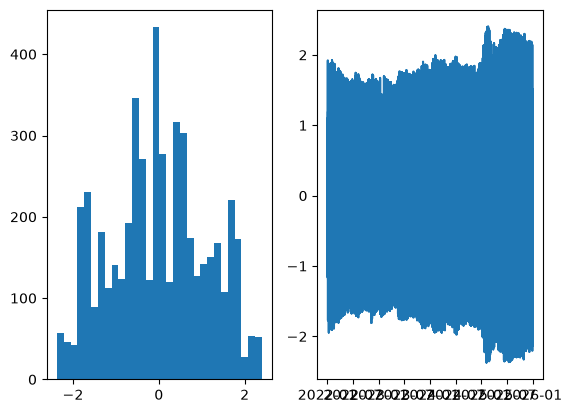

In [135]:
# Task 8
fig, axes = plt.subplots(1,2)
axes[0].hist(df["log_ret"], bins=30)
axes[1].plot(df["log_ret"])

plt.show()

In [136]:
# PART 2

In [184]:
# Task 1
companies = pd.read_csv("./data/companies_no_subindustry.csv")


In [185]:
companies["included"].isna().sum()

np.int64(45)

In [186]:
companies = companies.dropna(subset="included")

In [189]:
companies["included"] = pd.to_datetime(companies["included"], dayfirst=True, errors="coerce")
companies = companies.set_index("included").sort_index()

companies.head()

KeyError: 'included'

In [188]:

oldest = companies.loc[companies["founded"].idxmin()]

KeyError: 'founded'